# 01. 대조군 하나, 약물 하나: 정답 Δ는 어떻게 만들어지는가

이 노트북은 연구 B의 "정답"이 무엇인지 실제 숫자로 보여 준다.

- **X0**: 약물을 넣지 않고 용매(DMSO)만 넣은 well들의 발현을 같은 plate 안에서 평균한 값이다.
- **X1**: 같은 plate에서 약물 하나를 10 µM로 24시간 처리한 well들의 발현 평균이다.
- **Δ = X1 − X0**: 약물 때문에 생긴 변화다. 모델이 맞혀야 하는 값이다.

발현 값은 L1000 Level 3의 978개 landmark 유전자이며 추가 정규화를 하지 않았다.
여기서는 대상 HCC 세포주의 **적응용(adapt) 약물** 하나를 예로 쓴다. 시험(test) 약물은 열지 않는다.

In [1]:
import os, json, sys
import numpy as np, pandas as pd
import matplotlib
import matplotlib.pyplot as plt
ROOT = os.environ.get("TB_ROOT", os.path.abspath(os.path.join(os.getcwd(), "..", "..")) if os.path.basename(os.getcwd()) == "transigen_adaptation_b1" else os.getcwd())
os.chdir(ROOT); sys.path.insert(0, ROOT)
pd.set_option("display.width", 160); pd.set_option("display.float_format", lambda v: f"{v:.3f}")
BLUE, ORANGE, AQUA, YELLOW, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#8a8983"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "axes.axisbelow": True,
                     "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.edgecolor": "#8a8983", "font.size": 10,
                     "lines.linewidth": 2, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb"})
MAN = "manifests/transigen_adaptation_b1"
summ = json.load(open(f"{MAN}/splits_summary.json"))["targets"]
TARGET = next(t for t in ["HUH7", "JHH7", "JHH5"] if summ.get(t, {}).get("status", "excluded") != "excluded")
SPLIT = 1
print("example target:", TARGET, "| split seed:", SPLIT)

example target: HUH7 | split seed: 1


In [2]:
from src.transigen_adaptation_b1.data import Data
D = Data(verify_hashes=False)
rows = D.target_rows(TARGET, SPLIT, "adapt", k=8)          # 적응용 약물 8개에 해당하는 행
meta = D.rows.iloc[rows]
print(meta[["cell", "pert_id", "det_plate", "n_trt_wells", "n_ctl_wells"]].head(6).to_string(index=False))

cell       pert_id                           det_plate  n_trt_wells  n_ctl_wells
HUH7 BRD-A11731846 CVD001_HUH7_24H_X2_F1B3_DUO52HI53LO            1           13
HUH7 BRD-K25394294 CVD001_HUH7_24H_X2_F1B3_DUO52HI53LO            1           13
HUH7 BRD-K37392901 CVD001_HUH7_24H_X2_F1B3_DUO52HI53LO            1           13
HUH7 BRD-K37392901 CVD001_HUH7_24H_X3_F1B3_DUO52HI53LO            1           14
HUH7 BRD-K59469039 CVD001_HUH7_24H_X1_F1B3_DUO52HI53LO            1           12
HUH7 BRD-K65997856 CVD001_HUH7_24H_X2_F1B3_DUO52HI53LO            1           13


표의 한 줄이 **(세포주, 약물, plate)** 하나다. `n_ctl_wells`는 그 plate에서 평균에 들어간 DMSO well 수, `n_trt_wells`는 약물 well 수다.

이제 첫 번째 약물 하나를 골라 X0, X1, Δ를 본다.

In [3]:
pid = meta.pert_id.iloc[0]
r = meta[meta.pert_id == pid].row_id.to_numpy()                 # 이 약물의 plate별 행
x0 = np.asarray(D.x0[r])                                         # (plate 수, 978)
x1 = D.target_x1(r, TARGET, SPLIT, "adapt")                      # 적응용 행만 허용된다
name = D.drugs.set_index("pert_id").cmap_name[pid]
print("약물:", pid, "/", name, "| plate 수:", len(r), "| X0 모양:", x0.shape, "| X1 모양:", x1.shape)
delta_plate = x1 - x0
delta = delta_plate.mean(0)                                      # plate별 Δ를 똑같은 비중으로 평균 -> 조건의 정답
top = np.argsort(-np.abs(delta))[:10]
tab = pd.DataFrame({"gene": D.genes.gene_symbol.to_numpy()[top], "X0 (첫 plate)": x0[0, top], "X1 (첫 plate)": x1[0, top],
                    "Δ (첫 plate)": delta_plate[0, top], "Δ (plate 평균 = 정답)": delta[top]})
tab

약물: BRD-A11731846 / brd-a11731846 | plate 수: 1 | X0 모양: (1, 978) | X1 모양: (1, 978)


,gene,X0 (첫 plate),X1 (첫 plate),Δ (첫 plate),Δ (plate 평균 = 정답)
0,JMJD6,12.081,4.479,-7.601,-7.601
1,SYK,4.514,11.663,7.150,7.150
2,LPGAT1,11.016,4.120,-6.896,-6.896
3,ADRB2,4.671,11.213,6.543,6.543
4,TSPAN4,11.350,5.345,-6.004,-6.004
5,CLTB,12.143,6.746,-5.397,-5.397
6,MAP7,8.148,12.205,4.057,4.057
7,RGS2,7.000,10.851,3.851,3.851
8,COL1A1,4.645,7.718,3.074,3.074
9,CDKN1B,11.682,8.740,-2.942,-2.942


- 값 8~12 근처의 숫자가 발현 수준이고, Δ는 그 차이다. 대부분의 유전자에서 Δ는 0에 가깝고 일부 유전자만 크게 변한다.
- 위 10개는 이 약물에서 변화의 절댓값이 가장 큰 유전자다. 통계적으로 검정한 DEG가 아니다.
- plate가 여러 장이면 plate마다 Δ를 구한 다음 평균한다. plate가 한 장뿐인 세포주에서는 그 한 장의 Δ가 곧 정답이다.

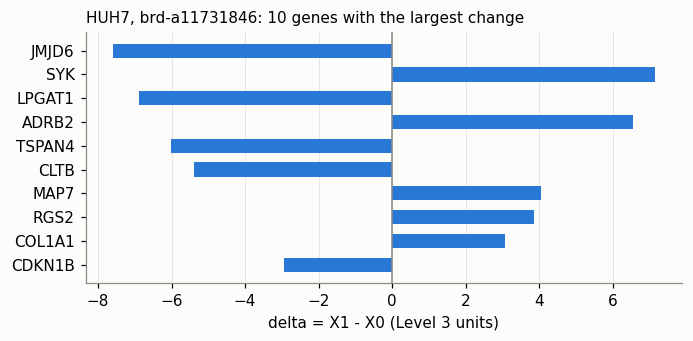

978개 유전자 전체에서 |Δ|의 중앙값: 0.334 | 최댓값: 7.601


In [4]:
fig, ax = plt.subplots(figsize=(6.4, 3.2))
ax.barh(tab.gene[::-1], tab["Δ (plate 평균 = 정답)"][::-1], color=BLUE, height=0.6)
ax.axvline(0, color=GREY, lw=1); ax.grid(axis="y", visible=False)
ax.set_xlabel("delta = X1 - X0 (Level 3 units)"); ax.set_title(f"{TARGET}, {name}: 10 genes with the largest change", loc="left", fontsize=10)
plt.tight_layout(); plt.show()
print("978개 유전자 전체에서 |Δ|의 중앙값:", round(float(np.median(np.abs(delta))), 3), "| 최댓값:", round(float(np.abs(delta).max()), 3))

## 정리

- 모델의 입력은 **X0와 약물 구조** 두 가지다. 출력은 X1의 예측이고, 거기서 X0를 빼면 예측한 Δ가 된다.
- 채점은 예측한 Δ와 위에서 만든 정답 Δ를 978개 유전자에서 비교한다(다음 노트북).
- X0를 계산할 때 약물 처리 well의 정보는 쓰지 않는다. X0는 처리 결과를 모르는 상태에서도 구할 수 있어야 하기 때문이다.